OPTIMIZER COMPARISON - SMALL NETWORK

Using 2 cases for optimizer comparison
Training samples: 2200
Test samples: 550

Network: 3 → [16, 8] → 1
Parameters: 209
Samples/Parameters ratio: 10.5
✓ Levenberg-Marquardt is applicable

1. LEVENBERG-MARQUARDT
`xtol` termination condition is satisfied.
Function evaluations 632, initial cost 2.2401e+03, final cost 1.8763e+00, first-order optimality 5.54e-01.
Time: 2709.83s, Iterations: 632
Train R²: 0.9878
Test R²: 0.9751

2. L-BFGS
Epoch 0: Loss = 0.743078
Epoch 100: Loss = 0.003808
Epoch 200: Loss = 0.003025
Epoch 300: Loss = 0.002536
Epoch 400: Loss = 0.002319
Time: 16.74s
Train R²: 0.9835
Test R²: 0.9777

3. ADAM
Epoch 0: Loss = 1.495756
Epoch 1000: Loss = 0.041768
Epoch 2000: Loss = 0.025267
Epoch 3000: Loss = 0.016311
Epoch 4000: Loss = 0.011233
Time: 9.39s
Train R²: 0.9436
Test R²: 0.9364

OPTIMIZER COMPARISON SUMMARY

Network: 3 → [16, 8] → 1 (209 parameters)
Training samples: 2200

Optimizer                 Iters     Time   Train R²    T

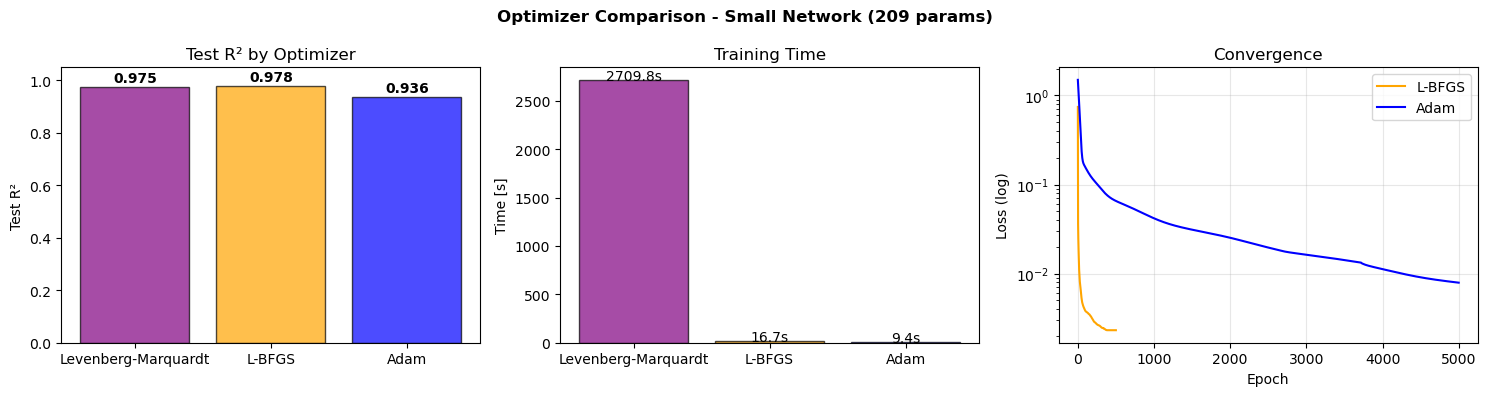


✓ Saved: optimizer_comparison_small_network.png
✓ Saved: optimizer_comparison_results.pkl


In [2]:
"""
OPTIMIZER COMPARISON ON SMALL NEURAL NETWORK
=============================================

Compare optimizers on a small network where Levenberg-Marquardt is applicable.
This is the classic system identification approach.

Network: 7 inputs → 16 → 8 → 1 output (~200 parameters)
Optimizers: Analytical (for reference), Levenberg-Marquardt, L-BFGS, Adam
"""

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error
import time
import pickle

from setup_paths import PROCESSED_DATA_DIR, FIGURES_DIR, REPORTS_DIR

# ============================================================================
# CONFIGURATION
# ============================================================================

INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_25_uniform.pkl'

# Small network - suitable for LM comparison
HIDDEN_SIZES = [16, 8]  # Small! ~200 parameters

MAX_EPOCHS = 5000
PATIENCE = 500
MIN_DELTA = 1e-7

H_CUBE = 0.015

# ============================================================================
# LOAD DATA (simplified - single case or subset)
# ============================================================================

print("="*70)
print("OPTIMIZER COMPARISON - SMALL NETWORK")
print("="*70)

with open(INPUT_FILE, 'rb') as f:
    all_cases_data = pickle.load(f)

# Use just 1-2 cases for cleaner comparison
case_ids = list(all_cases_data.keys())[:2]  # First 2 cases
print(f"\nUsing {len(case_ids)} cases for optimizer comparison")

# Extract data (simplified)
X_data = []
y_data = []

for case_id in case_ids:
    case_data = all_cases_data[case_id]
    U_ref = case_data['U_ref']
    
    for x_loc, profile in case_data['profiles'].items():
        for z_val, U_val in zip(profile['z'], profile['U_x']):
            x_norm = x_loc / H_CUBE
            z_norm = z_val / H_CUBE
            X_data.append([x_norm, z_norm, U_ref])
            y_data.append(U_val)

X_data = np.array(X_data, dtype=np.float32)
y_data = np.array(y_data, dtype=np.float32)

# Simple train/test split (80/20)
n_samples = len(X_data)
n_train = int(0.8 * n_samples)
indices = np.random.permutation(n_samples)

X_train = X_data[indices[:n_train]]
y_train = y_data[indices[:n_train]]
X_test = X_data[indices[n_train:]]
y_test = y_data[indices[n_train:]]

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

# Convert to tensors
X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train).reshape(-1, 1)
X_test_t = torch.tensor(X_test)
y_test_t = torch.tensor(y_test).reshape(-1, 1)

# ============================================================================
# SMALL NEURAL NETWORK
# ============================================================================

class SmallNet(nn.Module):
    def __init__(self, n_inputs=3, hidden_sizes=[16, 8]):
        super().__init__()
        layers = []
        prev = n_inputs
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.Tanh())
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)

# Check parameter count
test_model = SmallNet(n_inputs=3, hidden_sizes=HIDDEN_SIZES)
n_params = sum(p.numel() for p in test_model.parameters())
print(f"\nNetwork: 3 → {HIDDEN_SIZES} → 1")
print(f"Parameters: {n_params}")
print(f"Samples/Parameters ratio: {len(X_train)/n_params:.1f}")

if len(X_train) < n_params:
    print("⚠️  WARNING: Not enough samples for Levenberg-Marquardt!")
else:
    print("✓ Levenberg-Marquardt is applicable")

# ============================================================================
# HELPER FUNCTIONS FOR LEVENBERG-MARQUARDT
# ============================================================================

def get_params(model):
    return np.concatenate([p.detach().numpy().flatten() for p in model.parameters()])

def set_params(model, params):
    idx = 0
    for p in model.parameters():
        size = p.numel()
        p.data = torch.tensor(params[idx:idx+size].reshape(p.shape), dtype=torch.float32)
        idx += size

def lm_residuals(params, model, X, y):
    set_params(model, params)
    with torch.no_grad():
        y_pred = model(X).numpy().flatten()
    return y_pred - y.flatten()

# ============================================================================
# OPTIMIZER COMPARISON
# ============================================================================

results = {}

# ----------------------------------------------------------------------------
# 1. LEVENBERG-MARQUARDT
# ----------------------------------------------------------------------------
print(f"\n{'='*70}")
print("1. LEVENBERG-MARQUARDT")
print("="*70)

model_lm = SmallNet(n_inputs=3, hidden_sizes=HIDDEN_SIZES)
params0 = get_params(model_lm)

start = time.time()
result_lm = least_squares(
    lm_residuals, params0,
    method='lm',
    args=(model_lm, X_train_t, y_train),
    ftol=1e-8, xtol=1e-8, gtol=1e-8,
    max_nfev=10000,
    verbose=1
)
time_lm = time.time() - start

set_params(model_lm, result_lm.x)
with torch.no_grad():
    y_pred_train = model_lm(X_train_t).numpy().flatten()
    y_pred_test = model_lm(X_test_t).numpy().flatten()

results['Levenberg-Marquardt'] = {
    'train_R2': r2_score(y_train, y_pred_train),
    'test_R2': r2_score(y_test, y_pred_test),
    'train_RMSE': np.sqrt(mean_squared_error(y_train, y_pred_train)),
    'test_RMSE': np.sqrt(mean_squared_error(y_test, y_pred_test)),
    'time': time_lm,
    'iterations': result_lm.nfev
}
print(f"Time: {time_lm:.2f}s, Iterations: {result_lm.nfev}")
print(f"Train R²: {results['Levenberg-Marquardt']['train_R2']:.4f}")
print(f"Test R²: {results['Levenberg-Marquardt']['test_R2']:.4f}")

# ----------------------------------------------------------------------------
# 2. L-BFGS
# ----------------------------------------------------------------------------
print(f"\n{'='*70}")
print("2. L-BFGS")
print("="*70)

model_lbfgs = SmallNet(n_inputs=3, hidden_sizes=HIDDEN_SIZES)
optimizer = torch.optim.LBFGS(model_lbfgs.parameters(), lr=0.1, max_iter=20)
criterion = nn.MSELoss()

def closure():
    optimizer.zero_grad()
    loss = criterion(model_lbfgs(X_train_t), y_train_t)
    loss.backward()
    return loss

start = time.time()
losses_lbfgs = []
for epoch in range(500):
    loss = optimizer.step(closure)
    losses_lbfgs.append(loss.item())
    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.6f}")
    if loss.item() < 1e-6:
        break
time_lbfgs = time.time() - start

with torch.no_grad():
    y_pred_train = model_lbfgs(X_train_t).numpy().flatten()
    y_pred_test = model_lbfgs(X_test_t).numpy().flatten()

results['L-BFGS'] = {
    'train_R2': r2_score(y_train, y_pred_train),
    'test_R2': r2_score(y_test, y_pred_test),
    'train_RMSE': np.sqrt(mean_squared_error(y_train, y_pred_train)),
    'test_RMSE': np.sqrt(mean_squared_error(y_test, y_pred_test)),
    'time': time_lbfgs,
    'iterations': len(losses_lbfgs),
    'losses': losses_lbfgs
}
print(f"Time: {time_lbfgs:.2f}s")
print(f"Train R²: {results['L-BFGS']['train_R2']:.4f}")
print(f"Test R²: {results['L-BFGS']['test_R2']:.4f}")

# ----------------------------------------------------------------------------
# 3. ADAM
# ----------------------------------------------------------------------------
print(f"\n{'='*70}")
print("3. ADAM")
print("="*70)

model_adam = SmallNet(n_inputs=3, hidden_sizes=HIDDEN_SIZES)
optimizer = torch.optim.Adam(model_adam.parameters(), lr=0.001)
criterion = nn.MSELoss()

start = time.time()
losses_adam = []
for epoch in range(MAX_EPOCHS):
    optimizer.zero_grad()
    loss = criterion(model_adam(X_train_t), y_train_t)
    loss.backward()
    optimizer.step()
    losses_adam.append(loss.item())
    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.6f}")
    if loss.item() < 1e-6:
        break
time_adam = time.time() - start

with torch.no_grad():
    y_pred_train = model_adam(X_train_t).numpy().flatten()
    y_pred_test = model_adam(X_test_t).numpy().flatten()

results['Adam'] = {
    'train_R2': r2_score(y_train, y_pred_train),
    'test_R2': r2_score(y_test, y_pred_test),
    'train_RMSE': np.sqrt(mean_squared_error(y_train, y_pred_train)),
    'test_RMSE': np.sqrt(mean_squared_error(y_test, y_pred_test)),
    'time': time_adam,
    'iterations': len(losses_adam),
    'losses': losses_adam
}
print(f"Time: {time_adam:.2f}s")
print(f"Train R²: {results['Adam']['train_R2']:.4f}")
print(f"Test R²: {results['Adam']['test_R2']:.4f}")

# ============================================================================
# COMPARISON SUMMARY
# ============================================================================

print(f"\n{'='*70}")
print("OPTIMIZER COMPARISON SUMMARY")
print("="*70)
print(f"\nNetwork: 3 → {HIDDEN_SIZES} → 1 ({n_params} parameters)")
print(f"Training samples: {len(X_train)}")

print(f"\n{'Optimizer':<22s} {'Iters':>8s} {'Time':>8s} {'Train R²':>10s} {'Test R²':>10s}")
print("-" * 65)
for name, r in results.items():
    print(f"{name:<22s} {r['iterations']:>8d} {r['time']:>7.1f}s {r['train_R2']:>10.4f} {r['test_R2']:>10.4f}")

# Best
best = max(results.keys(), key=lambda x: results[x]['test_R2'])
print(f"\n✓ Best optimizer: {best} (Test R² = {results[best]['test_R2']:.4f})")

# ============================================================================
# VISUALIZATION
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Bar chart - Test R²
ax = axes[0]
names = list(results.keys())
test_r2 = [results[n]['test_R2'] for n in names]
colors = ['purple', 'orange', 'blue']
ax.bar(names, test_r2, color=colors, alpha=0.7, edgecolor='black')
ax.set_ylabel('Test R²')
ax.set_title('Test R² by Optimizer')
ax.set_ylim([0, 1.05])
for i, v in enumerate(test_r2):
    ax.text(i, v + 0.02, f'{v:.3f}', ha='center', fontweight='bold')

# Bar chart - Time
ax = axes[1]
times = [results[n]['time'] for n in names]
ax.bar(names, times, color=colors, alpha=0.7, edgecolor='black')
ax.set_ylabel('Time [s]')
ax.set_title('Training Time')
for i, v in enumerate(times):
    ax.text(i, v + 0.1, f'{v:.1f}s', ha='center')

# Convergence (L-BFGS vs Adam)
ax = axes[2]
if 'losses' in results['L-BFGS']:
    ax.semilogy(results['L-BFGS']['losses'], label='L-BFGS', color='orange')
if 'losses' in results['Adam']:
    ax.semilogy(results['Adam']['losses'], label='Adam', color='blue')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (log)')
ax.set_title('Convergence')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle(f'Optimizer Comparison - Small Network ({n_params} params)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'optimizer_comparison_small_network.png', dpi=300)
plt.show()
print(f"\n✓ Saved: optimizer_comparison_small_network.png")

# Save results
with open(REPORTS_DIR / 'optimizer_comparison_results.pkl', 'wb') as f:
    pickle.dump(results, f)
print(f"✓ Saved: optimizer_comparison_results.pkl")